# TUGAS OPERASI DASAR CITRA DIGITAL

## Penerapan Gaussian Blur dan Median Filter pada Citra Digital

**Mata Kuliah:** Operasi Dasar Citra Digital  
**Nama:** M. Awaludin Ramadan  
**NIM:** 24260027  
**Kelas:** Teknik Informatika 5.B  

### Deskripsi Tugas

Program ini dibuat untuk memenuhi tugas mata kuliah Operasi Dasar Citra Digital dengan menerapkan metode *Image Filtering* menggunakan Python pada Google Colab.

Metode yang digunakan adalah **Gaussian Blur** dan **Median Filter** untuk mengolah serta membandingkan citra asli dengan hasil pemrosesan. Analisis dilakukan melalui visualisasi gambar dan perhitungan statistik intensitas piksel.

### Tujuan

1. Memahami konsep dasar pengolahan citra digital.
2. Menerapkan metode Gaussian Blur dan Median Filter.
3. Membandingkan hasil pemrosesan citra secara visual.
4. Menganalisis perubahan nilai intensitas piksel.
5. Menarik kesimpulan berdasarkan hasil pengujian.

### Tools dan Library

- Python
- Google Colab
- OpenCV
- NumPy
- Matplotlib
- Pandas



Cell 1 — Import library

In [1]:
# OpenCV untuk mengolah citra digital
import cv2

# NumPy untuk perhitungan numerik dan array
import numpy as np

# Matplotlib untuk menampilkan gambar dan grafik
import matplotlib.pyplot as plt

# Pandas untuk membuat tabel hasil analisis
import pandas as pd

# Fitur upload file dari Google Colab
from google.colab import files

# Menampilkan tabel di notebook
from IPython.display import display

# Menampilkan versi OpenCV
print("Versi OpenCV:", cv2.__version__)

# Pesan bahwa library berhasil dimuat
print("Semua library berhasil diimpor.")


Versi OpenCV: 5.0.0
Semua library berhasil diimpor.


Cell ini menyiapkan seluruh library yang diperlukan untuk membaca gambar, melakukan filtering, menghitung statistik, dan menampilkan hasilnya.

Cell 2 — Upload dan membaca foto

In [5]:
# Meminta pengguna mengunggah foto
uploaded = files.upload()

# Memastikan file sudah dipilih
if not uploaded:
    raise ValueError("Silakan unggah sebuah file gambar.")

# Mengambil nama file yang diunggah
nama_file = next(iter(uploaded.keys()))

# Mengubah file menjadi array byte
data_file = np.frombuffer(
    uploaded[nama_file],
    dtype=np.uint8
)

# Membaca data gambar menggunakan OpenCV
citra_bgr = cv2.imdecode(
    data_file,
    cv2.IMREAD_COLOR
)

# Memastikan gambar berhasil dibaca
if citra_bgr is None:
    raise ValueError(
        "Gambar gagal dibaca. Gunakan format JPG, JPEG, atau PNG."
    )

# Mengubah format warna BGR menjadi RGB
citra_asli = cv2.cvtColor(
    citra_bgr,
    cv2.COLOR_BGR2RGB
)

# Menampilkan nama file
print("Nama file:", nama_file)

# Menampilkan pesan keberhasilan
print("Foto berhasil diunggah dan dibaca.")

Saving foto.jpeg to foto.jpeg
Nama file: foto.jpeg
Foto berhasil diunggah dan dibaca.


OpenCV membaca gambar dengan urutan kanal BGR, sedangkan Matplotlib menggunakan RGB. Karena itu, gambar dikonversi agar warna tampil dengan benar.

Cell 3 — Menampilkan informasi citra asli

Nama file: foto.jpeg
Tinggi citra: 1448 piksel
Lebar citra: 1086 piksel
Jumlah kanal: 3
Bentuk array: (1448, 1086, 3)
Tipe data: uint8
Ukuran array: 4717584 byte


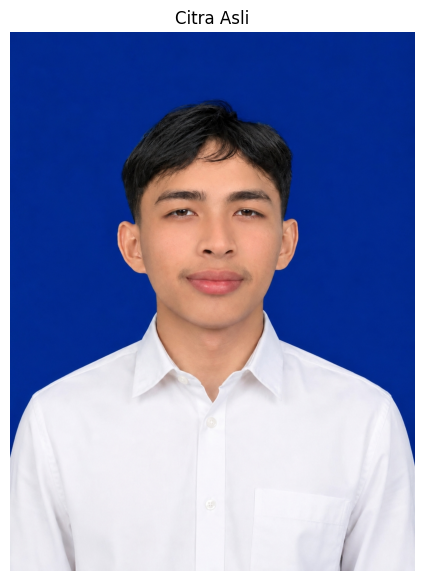

In [6]:
# Mengambil tinggi, lebar, dan jumlah kanal gambar
tinggi, lebar, kanal = citra_asli.shape

# Menampilkan nama file
print("Nama file:", nama_file)

# Menampilkan tinggi gambar
print("Tinggi citra:", tinggi, "piksel")

# Menampilkan lebar gambar
print("Lebar citra:", lebar, "piksel")

# Menampilkan jumlah kanal warna
print("Jumlah kanal:", kanal)

# Menampilkan bentuk array gambar
print("Bentuk array:", citra_asli.shape)

# Menampilkan tipe data piksel
print("Tipe data:", citra_asli.dtype)

# Menampilkan ukuran array dalam byte
print("Ukuran array:", citra_asli.nbytes, "byte")

# Membuat area tampilan gambar
plt.figure(figsize=(6, 7))

# Menampilkan gambar asli
plt.imshow(citra_asli)

# Memberikan judul gambar
plt.title("Citra Asli")

# Menghilangkan sumbu koordinat
plt.axis("off")

# Menampilkan gambar
plt.show()

Cell ini menampilkan informasi teknis citra, seperti dimensi, jumlah kanal warna, tipe data, dan ukuran array.

Cell 4 — Metode Gaussian Blur

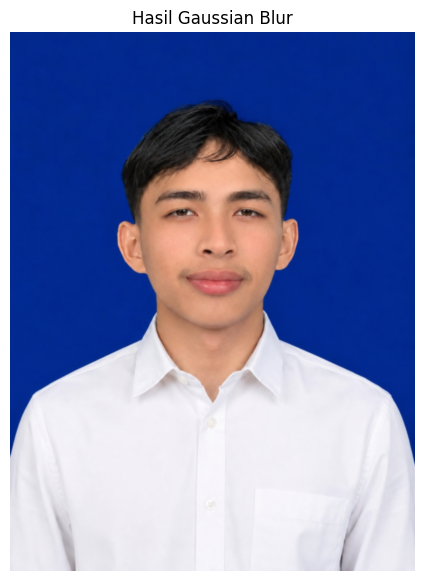

In [7]:
# Menerapkan Gaussian Blur pada citra asli
hasil_gaussian = cv2.GaussianBlur(
    citra_asli,       # Gambar yang akan diproses
    (5, 5),           # Ukuran kernel 5 x 5
    sigmaX=0          # Sigma ditentukan otomatis oleh OpenCV
)

# Membuat area tampilan gambar
plt.figure(figsize=(6, 7))

# Menampilkan hasil Gaussian Blur
plt.imshow(hasil_gaussian)

# Memberikan judul
plt.title("Hasil Gaussian Blur")

# Menghilangkan sumbu koordinat
plt.axis("off")

# Menampilkan hasil
plt.show()

-cv2.GaussianBlur() menjalankan proses penghalusan citra

-(5, 5) menentukan ukuran kernel yang digunakan untuk memproses lingkungan piksel

-sigmaX=0 membuat OpenCV menentukan sigma berdasarkan ukuran kernel

-hasil_gaussian menyimpan hasil tanpa mengubah citra asli

Cell 5 — Metode Median Filter

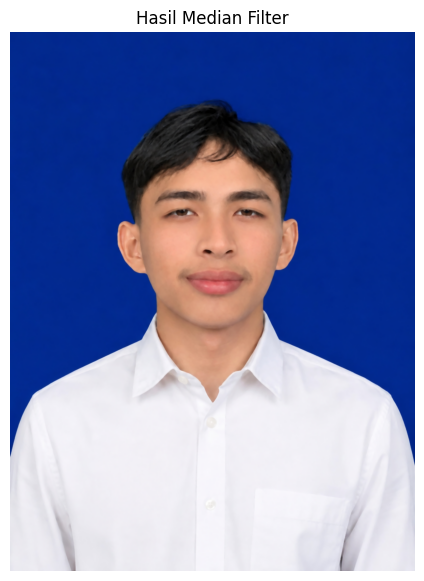

In [8]:
# Menerapkan Median Filter pada citra asli
hasil_median = cv2.medianBlur(
    citra_asli,       # Gambar yang akan diproses
    5                 # Ukuran kernel 5 x 5
)

# Membuat area tampilan gambar
plt.figure(figsize=(6, 7))

# Menampilkan hasil Median Filter
plt.imshow(hasil_median)

# Memberikan judul
plt.title("Hasil Median Filter")

# Menghilangkan sumbu koordinat
plt.axis("off")

# Menampilkan hasil
plt.show()

 Median Filter menggunakan nilai median dari lingkungan piksel berukuran 5 × 5 untuk menentukan nilai piksel hasil. Metode ini sering efektif mengurangi noise berbentuk bintik terang atau gelap, tetapi hasilnya bergantung pada karakteristik citra.

Cell 6 — Membandingkan ketiga gambar

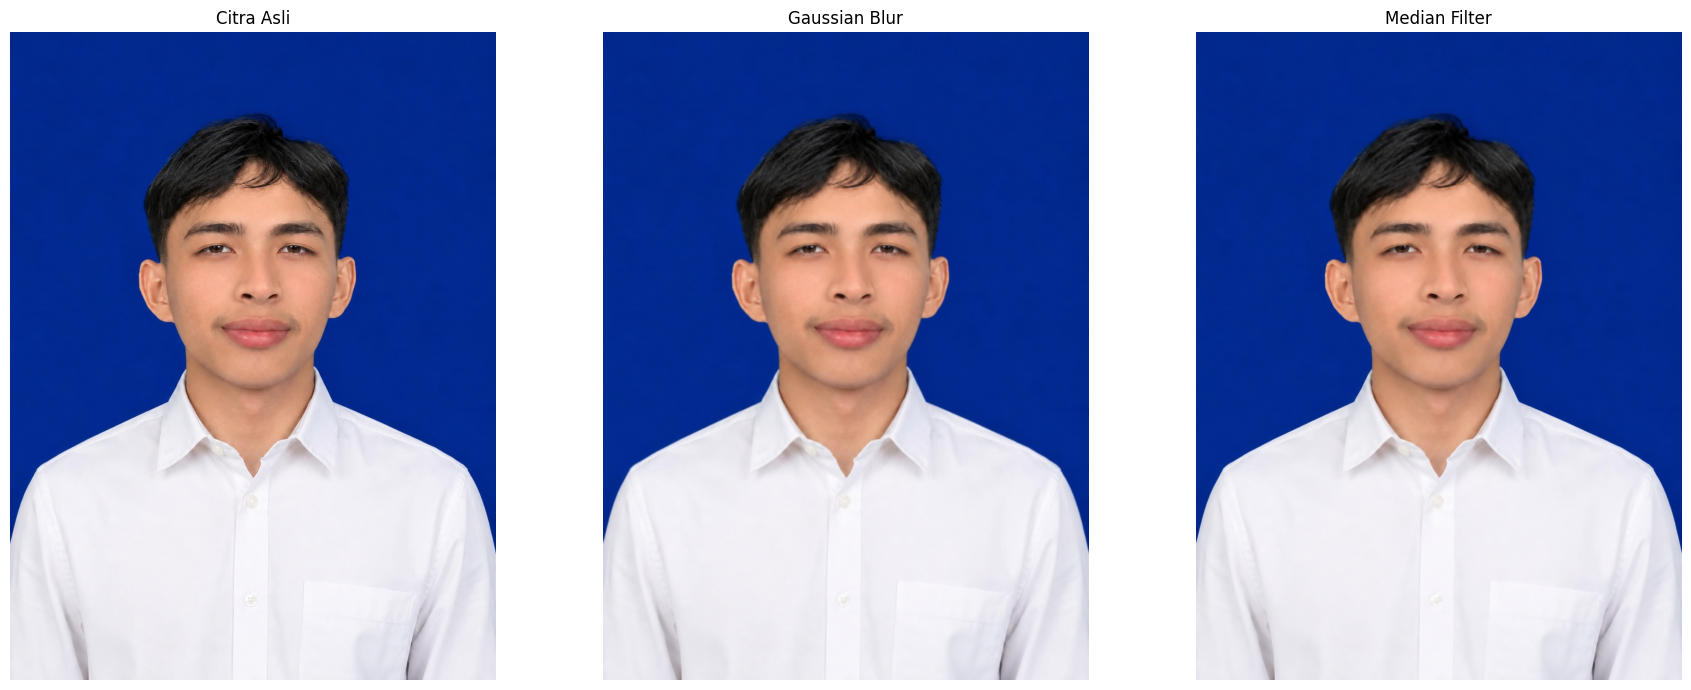

In [9]:
# Membuat tiga area gambar dalam satu baris
fig, axes = plt.subplots(
    1, 3,                 # Satu baris dan tiga kolom
    figsize=(18, 7)       # Ukuran keseluruhan tampilan
)

# Menyiapkan daftar gambar
daftar_gambar = [
    citra_asli,
    hasil_gaussian,
    hasil_median
]

# Menyiapkan judul setiap gambar
daftar_judul = [
    "Citra Asli",
    "Gaussian Blur",
    "Median Filter"
]

# Menampilkan setiap gambar dan judulnya
for ax, gambar, judul in zip(
    axes,
    daftar_gambar,
    daftar_judul
):
    # Menampilkan gambar
    ax.imshow(gambar)

    # Memberikan judul gambar
    ax.set_title(judul)

    # Menghilangkan sumbu
    ax.axis("off")

# Mengatur jarak antargambar
plt.tight_layout()

# Menampilkan perbandingan
plt.show()

Ketiga gambar ditampilkan berdampingan agar mudah mengamati perbedaan kehalusan, detail wajah, rambut, pakaian, dan latar belakang.

Cell 7 — Analisis nilai piksel

In [10]:
# Fungsi untuk menghitung statistik intensitas gambar
def analisis_citra(nama, gambar):

    # Mengubah gambar RGB menjadi grayscale
    grayscale = cv2.cvtColor(
        gambar,
        cv2.COLOR_RGB2GRAY
    )

    # Menghitung rata-rata intensitas piksel
    rata_rata = np.mean(grayscale)

    # Menghitung standar deviasi intensitas
    standar_deviasi = np.std(grayscale)

    # Mengembalikan hasil analisis
    return {
        "Nama Citra": nama,
        "Rata-rata Intensitas": round(
            float(rata_rata), 3
        ),
        "Standar Deviasi": round(
            float(standar_deviasi), 3
        )
    }


# Menganalisis citra asli
data_asli = analisis_citra(
    "Citra Asli",
    citra_asli
)

# Menganalisis hasil Gaussian Blur
data_gaussian = analisis_citra(
    "Gaussian Blur",
    hasil_gaussian
)

# Menganalisis hasil Median Filter
data_median = analisis_citra(
    "Median Filter",
    hasil_median
)

# Menggabungkan hasil analisis
data_tabel = [
    data_asli,
    data_gaussian,
    data_median
]

# Membuat tabel menggunakan Pandas
tabel_hasil = pd.DataFrame(data_tabel)

# Menampilkan tabel
display(tabel_hasil)

,Nama Citra,Rata-rata Intensitas,Standar Deviasi
0,Citra Asli,127.614,91.817
1,Gaussian Blur,127.582,91.682
2,Median Filter,127.605,91.748


Cell 8 — Analisis dan Visualisasi Statistik Intensitas Piksel

Untuk mempermudah analisis perbandingan efek dari Gaussian Blur dan Median Filter terhadap citra asli, kita dapat memvisualisasikan data dari `tabel_hasil` menggunakan grafik batang (bar chart).

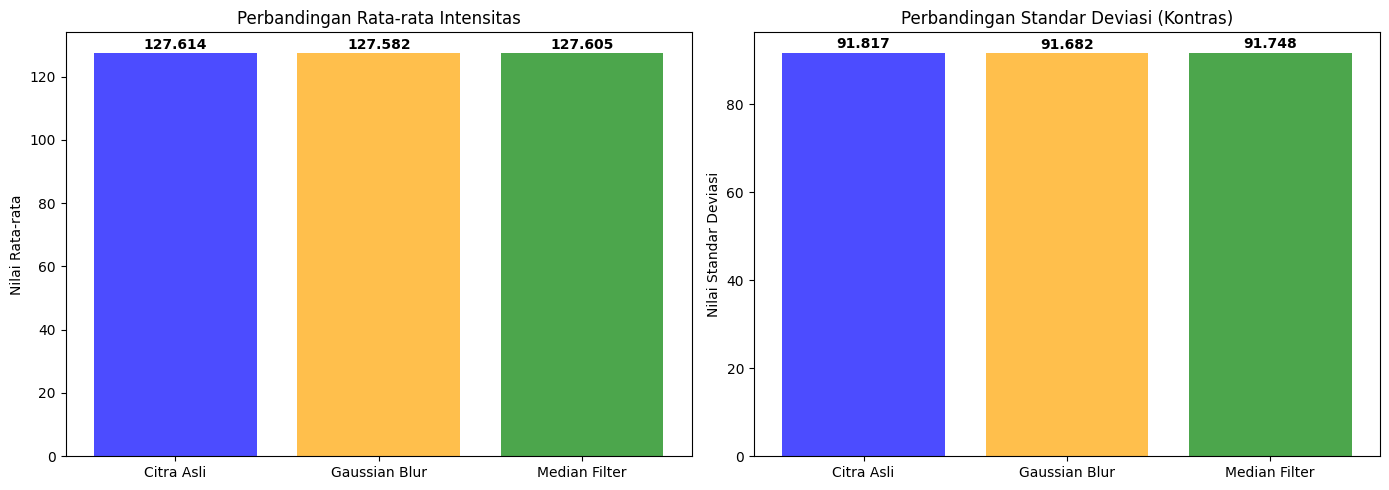

In [14]:
# Membuat visualisasi grafik batang untuk perbandingan statistik
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Batang Rata-rata Intensitas
axes[0].bar(tabel_hasil['Nama Citra'], tabel_hasil['Rata-rata Intensitas'], color=['blue', 'orange', 'green'], alpha=0.7)
axes[0].set_title('Perbandingan Rata-rata Intensitas')
axes[0].set_ylabel('Nilai Rata-rata')
for i, v in enumerate(tabel_hasil['Rata-rata Intensitas']):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

# Grafik Batang Standar Deviasi
axes[1].bar(tabel_hasil['Nama Citra'], tabel_hasil['Standar Deviasi'], color=['blue', 'orange', 'green'], alpha=0.7)
axes[1].set_title('Perbandingan Standar Deviasi (Kontras)')
axes[1].set_ylabel('Nilai Standar Deviasi')
for i, v in enumerate(tabel_hasil['Standar Deviasi']):
    axes[1].text(i, v + 1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

Cell 9 — Kesimpulan

In [16]:
# Menampilkan judul kesimpulan
print("KESIMPULAN OPERASI DASAR CITRA DIGITAL")
print("=" * 45)

# Menampilkan rata-rata intensitas citra asli
print(
    "Rata-rata citra asli:",
    data_asli["Rata-rata Intensitas"]
)

# Menampilkan rata-rata intensitas Gaussian Blur
print(
    "Rata-rata Gaussian Blur:",
    data_gaussian["Rata-rata Intensitas"]
)

# Menampilkan rata-rata intensitas Median Filter
print(
    "Rata-rata Median Filter:",
    data_median["Rata-rata Intensitas"]
)

# Menjelaskan metode Gaussian Blur
print("\n1. Gaussian Blur")
print(
    "Menghaluskan citra menggunakan pembobotan Gaussian."
)

# Menjelaskan metode Median Filter
print("\n2. Median Filter")
print(
    "Mengganti nilai piksel berdasarkan median lingkungan lokal."
)

# Menampilkan kesimpulan umum
print("\n3. Kesimpulan")
print(
    "Kedua metode menghasilkan pengolahan citra yang berbeda."
)

print(
    "Pemilihan metode bergantung pada tujuan dan karakteristik citra."
)

print(
    "Hasil statistik perlu dilengkapi dengan pengamatan visual."
)

KESIMPULAN OPERASI DASAR CITRA DIGITAL
Rata-rata citra asli: 127.614
Rata-rata Gaussian Blur: 127.582
Rata-rata Median Filter: 127.605

1. Gaussian Blur
Menghaluskan citra menggunakan pembobotan Gaussian.

2. Median Filter
Mengganti nilai piksel berdasarkan median lingkungan lokal.

3. Kesimpulan
Kedua metode menghasilkan pengolahan citra yang berbeda.
Pemilihan metode bergantung pada tujuan dan karakteristik citra.
Hasil statistik perlu dilengkapi dengan pengamatan visual.
